# 60 秒 DAS 数据：f-k 方向滤波

读取和预处理参照 `das_veh.ipynb`：小端 float32、80 字节文件头、通道优先排列，按采样点数跨文件拼接；四阶 Butterworth 双向带通、公共模态去除、逐通道 MAD 归一化。

默认分析参考文件开头的 **0–60 秒、291–520 通道**。前后额外读取 100 秒用于低频滤波，f-k 使用目标窗口前后各 5 秒。文件按采样点连续拼接，不用文件名中取整的秒数补间隙。

图中时间向右、通道号向上。去掉 **ΔChannel / Δt > 0**（右上方向），保留 **ΔChannel / Δt < 0**（右下方向）。本例只进行方向滤波，不找峰、不提取轨迹。


In [57]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal, fft

data_dir = Path(r'D:\projects\das\下午')  # 原始 BIN 数据目录
source_file = data_dir / 'ch1_2026-09-05-13-51-27_2_30720_520_1000.bin'  # 与原 Notebook 相同的参考文件
window_start = 0.0  # 相对参考文件起点的开始时间，单位 s
duration = 4.0  # 目标数据时长，单位 s
channel_from = 291  # 起始通道号，从 1 开始，包含该通道
channel_to = 520  # 结束通道号，包含该通道
frequency_low = 0.01  # 带通下限，单位 Hz
frequency_high = 1.0  # 带通上限，单位 Hz
channel_spacing = 4.0  # 通道间距，单位 m
minimum_speed_kmh = 0.0  # f-k 表观速度下限，单位 km/h；0 表示不额外排除慢速成分
maximum_speed_kmh = 120.0  # f-k 表观速度上限，单位 km/h；两个方向都使用该范围
padding_seconds = 1 / frequency_low  # 带通前后读取一个最低频率周期，即 100 s
fk_padding_seconds = 5.0  # f-k 使用目标窗口前后各 5 s 的真实数据
padding_channels = 16  # f-k 在通道两端各反射扩展 16 个通道
taper_fraction = 0.1  # Tukey 窗两端渐变部分合计占 10%，即每端 5%
transition_bins = 2.0  # 频率、波数零轴附近各用 2 个频谱格点平滑过渡；越大衰减范围越宽


In [58]:
files = sorted(data_dir.glob('*.bin'))  # 按时间顺序排列的 BIN 路径
if source_file not in files:
    raise FileNotFoundError(source_file)

headers = []  # 各文件的 20 个 float32 文件头
for path in files:  # path：当前文件路径
    headers.append(np.fromfile(path, dtype='<f4', count=20))

anchor_index = files.index(source_file)  # 参考文件在列表中的位置
sampling_rate = float(headers[anchor_index][9])  # 采样率，单位 Hz
num_channels = int(headers[anchor_index][8])  # 文件中的总通道数
frames = []  # 各文件每通道的采样点数
for header in headers:  # header：当前文件头
    if len(header) != 20 or header[8] != num_channels or header[9] != sampling_rate:
        raise ValueError('文件头不完整，或文件间通道数、采样率不一致')
    frames.append(int(header[7]))

#boundaries = [0, 30720, 61440, 92160]
boundaries = np.r_[0, np.cumsum(frames)]  # 各文件在连续采样轴上的边界
anchor_sample = int(boundaries[anchor_index])  # 参考文件起点的全局采样编号
first_sample = anchor_sample + round((window_start - padding_seconds) * sampling_rate)  # 含前置数据的读取起点
last_sample = anchor_sample + round((window_start + duration + padding_seconds) * sampling_rate)  # 含后置数据的读取终点
if first_sample < 0 or last_sample > boundaries[-1]:
    raise ValueError('前后数据不足，请选择目录中间的参考文件')
if not 1 <= channel_from <= channel_to <= num_channels:
    raise ValueError('所选通道范围超出文件中的通道范围')

blocks = []  # 各文件与读取区间重合的数据块
for index, path in enumerate(files):  # index：文件序号；path：文件路径
    left = max(first_sample, int(boundaries[index]))  # 当前文件内读取区间的全局起点
    right = min(last_sample, int(boundaries[index + 1]))  # 当前文件内读取区间的全局终点
    if left < right:
        mapped = np.memmap(path, dtype='<f4', mode='r', offset=80,
                           shape=(num_channels, frames[index]))  # 只读的“通道 × 时间”数据
        blocks.append(mapped[:, left - boundaries[index]:right - boundaries[index]])
        print('读取：', path.name)

raw_data = np.concatenate(blocks, axis=1)  # 拼接后的原始数据，包含前后各 100 s
sample_origin = first_sample - anchor_sample  # 读取起点相对参考文件的采样偏移，可为负
del blocks, mapped
print('含滤波上下文的数据：', raw_data.shape, '；采样率：', sampling_rate, 'Hz')


读取： ch1_2026-09-05-13-49-24_2_30720_520_1000.bin
读取： ch1_2026-09-05-13-49-55_2_30720_520_1000.bin
读取： ch1_2026-09-05-13-50-25_2_30720_520_1000.bin
读取： ch1_2026-09-05-13-50-56_2_30720_520_1000.bin
读取： ch1_2026-09-05-13-51-27_2_30720_520_1000.bin
读取： ch1_2026-09-05-13-51-58_2_30720_520_1000.bin
读取： ch1_2026-09-05-13-52-28_2_30720_520_1000.bin
读取： ch1_2026-09-05-13-52-59_2_30720_520_1000.bin
含滤波上下文的数据： (520, 204000) ；采样率： 1000.0 Hz


In [59]:
sos = signal.iirfilter(4, [frequency_low, frequency_high], fs=sampling_rate,
                       btype='bandpass', ftype='butter', output='sos')  # 恢复原版 0.01-1.0 Hz
filtered = np.empty_like(raw_data)
for row in range(0, num_channels, 8):
    block = signal.sosfilt(sos, raw_data[row:row + 8], axis=1)
    filtered[row:row + 8] = signal.sosfilt(sos, block[:, ::-1], axis=1)[:, ::-1]

common = np.median(filtered, axis=0)
energy = float(np.sum(common ** 2))
if energy > np.finfo(float).eps:
    for row in range(num_channels):
        projection = np.sum(filtered[row] * common) / energy
        filtered[row] -= projection * common

data = filtered[channel_from - 1:channel_to].copy()
for row in range(len(data)):
    trace = data[row].astype(float)
    centered = trace - np.median(trace)
    mad = np.median(np.abs(centered))
    tolerance = np.finfo(float).eps * max(np.max(np.abs(trace)), np.finfo(float).tiny)
    if mad > tolerance:
        data[row] = centered / (1.4826 * mad)
    else:
        data[row] = 0
print('预处理完成：', data.shape)

预处理完成： (230, 204000)




使用 NumPy/SciPy 的 FFT 定义，平面波 `cos(2π(ft + kx))` 的运动速度为 `dx/dt = -f/k`。去掉右上方向对应的 **f × k < 0** 象限和零频轴，只在 **f × k > 0** 的象限内保留信号。

在保留象限内，靠近频率和波数零轴的权重采用半余弦渐变，从 0 平滑升到 1；默认过渡宽度为各轴的 2 个频谱格点。反方向始终为零。加大 transition_bins 会扩大衰减范围，也可能削弱低频或低波数的真实信号。

两个方向都限制表观速度绝对值 abs(f/k) 在 0–120 km/h 内。速度边界也在允许区域内采用半余弦过渡，边界处衰减至零，超范围严格置零。下限为 0 时不增加慢速截止，但仍保留原有零频轴置零规则。f-k 表观速度依赖通道间距，不等同于逐辆车拟合出的真实车速。

目标窗口两侧使用真实数据，通道两端反射扩展并加 Tukey 窗，以减轻边界影响。正、负频率成对处理；偶数长度的 Nyquist 行、列仍置零，保证共轭对称。平滑象限边界用于减轻硬截断振铃，不能保证消除全部残留条纹。


In [60]:
first = round(window_start * sampling_rate) - sample_origin
last = first + round(duration * sampling_rate)
time_padding = round(fk_padding_seconds * sampling_rate)

fk_input = data[:, first - time_padding:last + time_padding].copy()

# 通道两端使用线性衰减到0的填充（避免 reflect 把右下斜线折反射成右上斜线）
pad_ch = padding_channels
padded = np.pad(fk_input, ((pad_ch, pad_ch), (0, 0)), mode='edge')
ramp = np.linspace(0, 1, pad_ch, dtype=np.float32)
padded[:pad_ch, :] *= ramp[:, None]
padded[-pad_ch:, :] *= ramp[::-1, None]

# 时间方向仅在前后 5s padding 区加余弦窗，中间 60s 权重严格为 1.0
time_window = np.ones(padded.shape[1], dtype=np.float32)
t_ramp = 0.5 * (1 - np.cos(np.pi * np.arange(time_padding) / time_padding))
time_window[:time_padding] = t_ramp
time_window[-time_padding:] = t_ramp[::-1]
padded *= time_window[None, :]

# 2D FFT
spectrum = fft.fft2(padded)
frequency = fft.fftfreq(padded.shape[1], d=1 / sampling_rate)
wavenumber = fft.fftfreq(padded.shape[0], d=channel_spacing)

# 归一化格点坐标 (以格点 bin 为单位计算极角，避免物理量纲失衡)
df = sampling_rate / padded.shape[1]
dk = 1 / (padded.shape[0] * channel_spacing)
K_bin = wavenumber[:, None] / dk
F_bin = frequency[None, :] / df

# 核心改进：使用归一化频率-波数平面上的角度平滑过渡，不在零轴挖坑！
# 目标象限：K_bin * F_bin > 0 (第一、三象限，对应右下方向 dx/dt < 0)
# 利用 K_bin * F_bin / (K_bin^2 + F_bin^2 + eps) 构建平滑角度掩码：
# 在象限内部为 1，在零轴上恰好为 0.5（无失真保留包络基准），在反方向象限为 0
eps = 1e-6
sin_2theta = (2.0 * K_bin * F_bin) / (K_bin**2 + F_bin**2 + eps)

# transition_width 控制象限交界线处的平滑锐度（0.15 表示仅在贴近坐标轴约 4 度角内平滑过渡到 0.5）
transition_width = 0.15
keep_mask = np.clip((sin_2theta + transition_width) / (2.0 * transition_width), 0.0, 1.0).astype(np.float32)
keep_mask = 0.5 - 0.5 * np.cos(np.pi * keep_mask)

# 原点 (0, 0) 直流分量保持 0.5 或 0
keep_mask[0, 0] = 0.0

# 适度限制极高视速度（例如 > 150 km/h 的纯水平光路闪烁噪声），过渡带设窄，绝不伤及 70 km/h 车流
max_v_ms = 150.0 / 3.6
speed_margin = max_v_ms * np.abs(wavenumber[:, None]) - np.abs(frequency[None, :])
speed_weight = np.clip(speed_margin / (1.0 * df), 0.0, 1.0).astype(np.float32)
keep_mask *= (0.5 - 0.5 * np.cos(np.pi * speed_weight))

# 保持偶数 Nyquist 对称
if padded.shape[0] % 2 == 0:
    keep_mask[padded.shape[0] // 2, :] = 0
if padded.shape[1] % 2 == 0:
    keep_mask[:, padded.shape[1] // 2] = 0

spectrum *= keep_mask

restored = fft.ifft2(spectrum).real
before_fk = data[:, first:last].copy()
after_fk = restored[pad_ch:pad_ch + len(data),
                    time_padding:time_padding + last - first].copy()

del spectrum, padded, restored, keep_mask
print('f-k 输出：', after_fk.shape, '；时长：', after_fk.shape[1] / sampling_rate, 's')

f-k 输出： (230, 4000) ；时长： 4.0 s


## 4. 查看滤波前后

两幅图使用相同的色标和全部时间采样点，便于比较。横轴相对参考文件起点计时，纵轴通道号向上增加。滤波后峰的位置和幅度可能变化；后续找峰时应明确使用 `after_fk`。


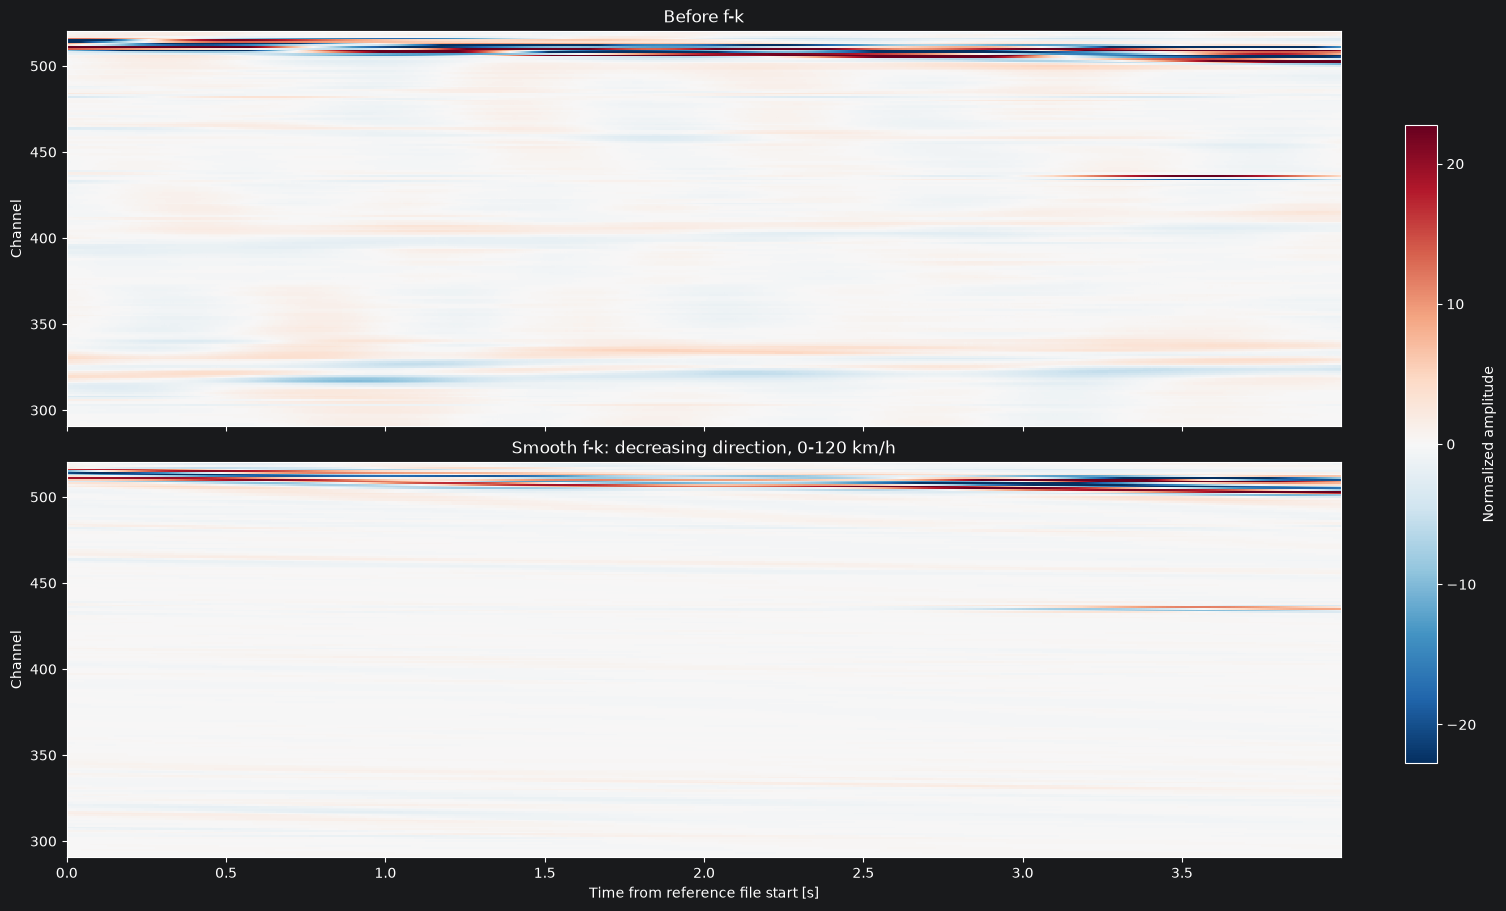

In [61]:
color_limit = max(float(np.percentile(np.abs(before_fk), 99)), 1e-8)  # 两幅图共用的幅度范围
extent = [window_start - 0.5 / sampling_rate,
          window_start + duration - 0.5 / sampling_rate,
          channel_from - 0.5, channel_to + 0.5]  # 图像的时间、通道坐标边界
fig, axes = plt.subplots(2, 1, figsize=(15, 9), sharex=True,
                         sharey=True, layout='constrained')  # 对比图及上下两个子图
for ax, values, title in zip(axes, [before_fk, after_fk],
                             ['Before f-k', f'Smooth f-k: decreasing direction, {minimum_speed_kmh:g}-{maximum_speed_kmh:g} km/h']):  # ax：子图；values：数据；title：标题
    image = ax.imshow(values, origin='lower', aspect='auto', cmap='RdBu_r',
                      extent=extent, vmin=-color_limit, vmax=color_limit,
                      interpolation='none')  # 使用统一色标的时间—通道图
    ax.set(title=title, ylabel='Channel')
axes[-1].set_xlabel('Time from reference file start [s]')
fig.colorbar(image, ax=axes, label='Normalized amplitude', fraction=0.025)
plt.show()


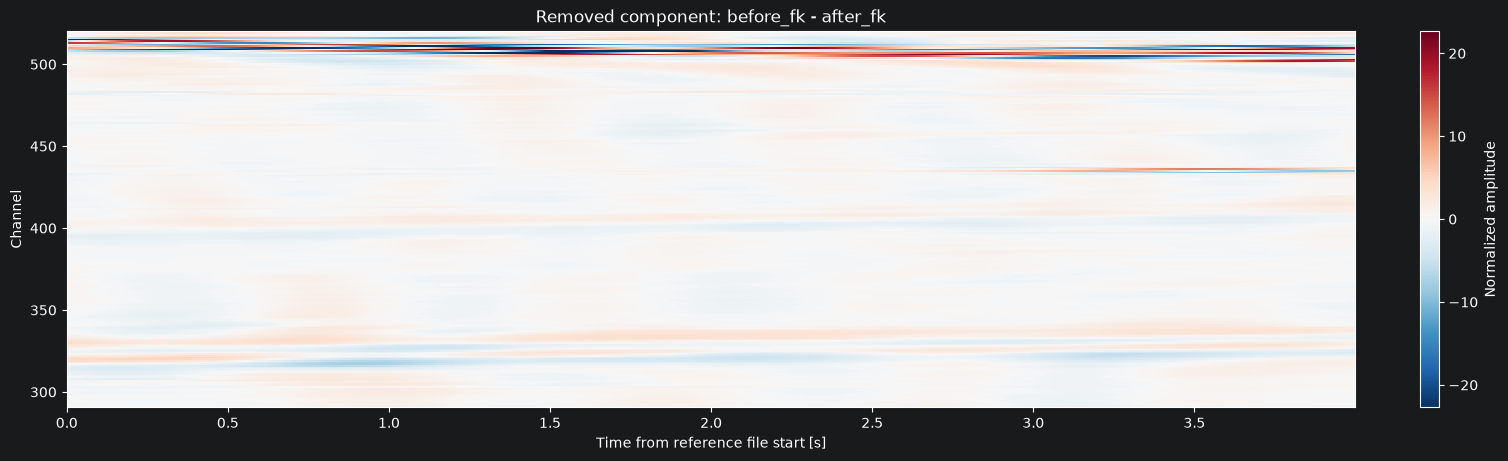

In [62]:
removed_fk = before_fk - after_fk  # 被 f-k 滤波去掉的成分，与原数据形状相同
fig_removed, ax_removed = plt.subplots(figsize=(15, 4.5), layout='constrained')  # 差值图及坐标轴
image_removed = ax_removed.imshow(
    removed_fk, origin='lower', aspect='auto', cmap='RdBu_r',
    extent=extent, vmin=-color_limit, vmax=color_limit,
    interpolation='none')  # 沿用前面对比图的坐标和色标
ax_removed.set(title='Removed component: before_fk - after_fk',
               xlabel='Time from reference file start [s]', ylabel='Channel')
fig_removed.colorbar(image_removed, ax=ax_removed, label='Normalized amplitude')
plt.show()


In [63]:
# 先运行前面的 f-k 单元格；沿用频率坐标、渐变窗、半余弦权重和速度约束。
padded_increasing = np.pad(fk_input, ((padding_channels, padding_channels), (0, 0)),
                           mode='reflect')  # 通道两端反射扩展后的数据
padded_increasing *= space_window[:, None]
padded_increasing *= time_window[None, :]

spectrum_increasing = fft.fft2(padded_increasing)  # 重新从预处理数据计算频谱
mask_increasing = (wavenumber[:, None] * frequency[None, :] < 0).astype(np.float32)  # 保留左下到右上方向，零频轴置零
mask_increasing *= wavenumber_weight[:, None]
mask_increasing *= frequency_weight[None, :]
mask_increasing *= speed_weight
if padded_increasing.shape[0] % 2 == 0:
    mask_increasing[padded_increasing.shape[0] // 2, :] = 0
if padded_increasing.shape[1] % 2 == 0:
    mask_increasing[:, padded_increasing.shape[1] // 2] = 0
spectrum_increasing *= mask_increasing

restored_increasing = fft.ifft2(spectrum_increasing).real  # 逆变换得到通道号随时间增加的波形
after_fk_increasing = restored_increasing[
    padding_channels:padding_channels + fk_input.shape[0],
    time_padding:time_padding + last - first].copy()  # 去掉扩展区域，只保留目标 60 秒
del padded_increasing, spectrum_increasing, mask_increasing, restored_increasing

fig_increasing, ax_increasing = plt.subplots(figsize=(15, 4.5), layout='constrained')  # 反方向轨迹图及坐标轴
image_increasing = ax_increasing.imshow(
    after_fk_increasing, origin='lower', aspect='auto', cmap='RdBu_r',
    extent=extent, vmin=-color_limit, vmax=color_limit,
    interpolation='none')  # 沿用前面对比图的坐标和色标
ax_increasing.set(title=f'Smooth f-k: increasing direction, {minimum_speed_kmh:g}-{maximum_speed_kmh:g} km/h',
                  xlabel='Time from reference file start [s]', ylabel='Channel')
fig_increasing.colorbar(image_increasing, ax=ax_increasing, label='Normalized amplitude')
plt.show()


ValueError: operands could not be broadcast together with shapes (262,14000) (1,70000) (262,14000) 